# Softmax attention experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [9]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [10]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [11]:
# Final experiment: repeat the layered/looped sweep with softmax attention.
# This uses the same seeds, counts, data mode, optimizer, training steps, and
# reusable loss/distance/parameter plotting helpers as the baseline experiment.
# Each configuration is trained with both 1 and 2 attention heads.
softmax_attention_type = 'softmax'
softmax_seeds = [0]
softmax_counts = [2, 5, 10]
softmax_model_types = ['looped']
softmax_context_lengths = [N]
softmax_data_modes = [normal_data_mode]
softmax_head_counts = [1, 2]
softmax_iterations = np.arange(0, max_iters, stride)

softmax_fig_dir = os.path.join('figures', 'softmax_attention')
os.makedirs(softmax_fig_dir, exist_ok=True)
softmax_heads_tag = '-'.join(str(head_count) for head_count in softmax_head_counts)
softmax_history_file = os.path.join(
    cur_dir, f'softmax_attention_N{N}_d{d}_heads{softmax_heads_tag}_histories.pth')
softmax_results_file = os.path.join(
    cur_dir, f'softmax_attention_N{N}_d{d}_heads{softmax_heads_tag}_results.pth')

softmax_hist_dict = run_experiment_suite(
    seeds=softmax_seeds,
    n_layers_loops=softmax_counts,
    model_types=softmax_model_types,
    filename=softmax_history_file,
    context_lengths=softmax_context_lengths,
    data_modes=softmax_data_modes,
    head_counts=softmax_head_counts,
    attention_type=softmax_attention_type,
    freeze_p=True,  # [P-FIX] paper's P = [[0, 0], [0, 1]]
)
softmax_loss_dict = compute_loss_dict(
    softmax_hist_dict,
    test_seed=TEST_SEED,
    attention_type=softmax_attention_type,
)


def filter_by_head_count(run_dict, head_count):
    """Keep only the runs in `run_dict` trained with `head_count` heads (key[5])."""
    return {key: value for key, value in run_dict.items() if key[5] == head_count}


# Distance-to-identity has to be computed per head count, since the number of
# heads determines how many P/Q blocks are averaged for each checkpoint.
softmax_dist_dicts = {
    head_count: compute_dist_dict(
        filter_by_head_count(softmax_hist_dict, head_count),
        softmax_iterations,
        n_head=head_count,
        hist_stride=hist_stride,
    )
    for head_count in softmax_head_counts
}

torch.save(
    {
        'config': {
            'N': N, 'd': d, 'B': B, 'head_counts': softmax_head_counts,
            'attention_type': softmax_attention_type,
            'data_modes': softmax_data_modes,
            'seeds': softmax_seeds, 'counts': softmax_counts,
            'model_types': softmax_model_types,
            'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
            'max_iters': max_iters, 'hist_stride': hist_stride,
            'stride': stride, 'test_seed': TEST_SEED,
        },
        'history_file': softmax_history_file,
        'hist_dict': softmax_hist_dict,
        'loss_dict': softmax_loss_dict,
        'distance_dicts': softmax_dist_dicts,
        'iterations': softmax_iterations,
    },
    softmax_results_file,
)
print(f'Saved softmax-attention experiment results to {softmax_results_file}')

Run 1/6: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=softmax, freeze_p=True, learn_u=False
iter 0 | Loss: 5.226809024810791 | time: 0.0086822509765625 | gradnorm: 0.6984212398529053
iter 1 | Loss: 4.795989036560059 | time: 0.007506370544433594 | gradnorm: 0.6541692614555359
iter 2 | Loss: 5.125550270080566 | time: 0.007643699645996094 | gradnorm: 0.74076247215271
iter 3 | Loss: 4.9741926193237305 | time: 0.007305622100830078 | gradnorm: 0.6964113712310791
iter 4 | Loss: 4.876002311706543 | time: 0.007612943649291992 | gradnorm: 0.6686122417449951
iter 100 | Loss: 4.725188732147217 | time: 0.0073397159576416016 | gradnorm: 0.7103671431541443
iter 200 | Loss: 4.850557804107666 | time: 0.00680851936340332 | gradnorm: 0.6963129639625549
iter 300 | Loss: 4.793399810791016 | time: 0.0071260929107666016 | gradnorm: 0.6317404508590698
iter 400 | Loss: 4.507288932800293 | time: 0.007649421691894

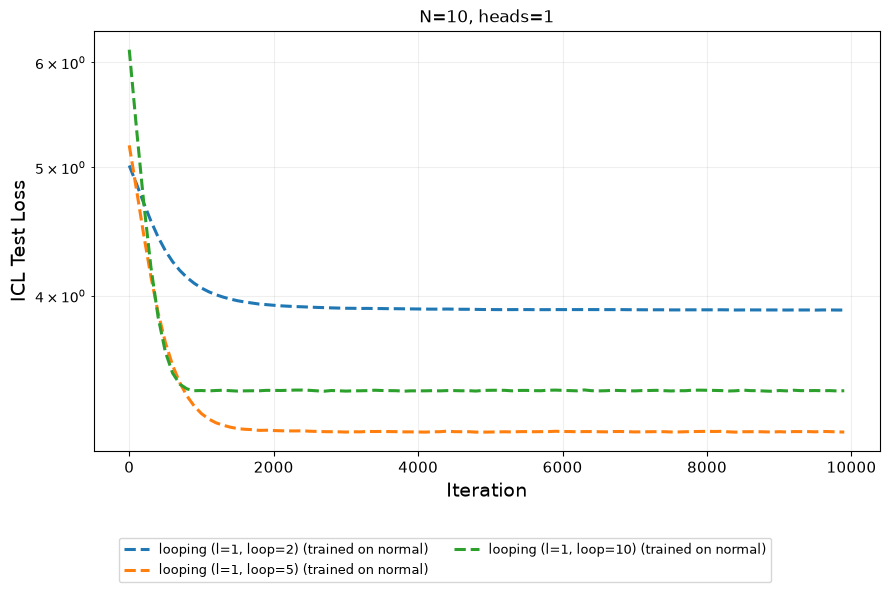

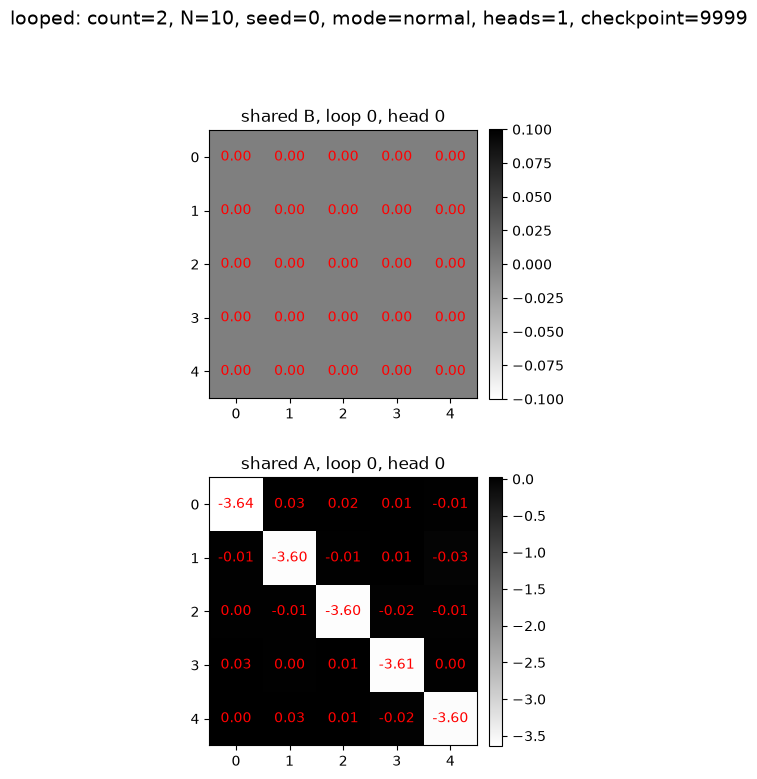

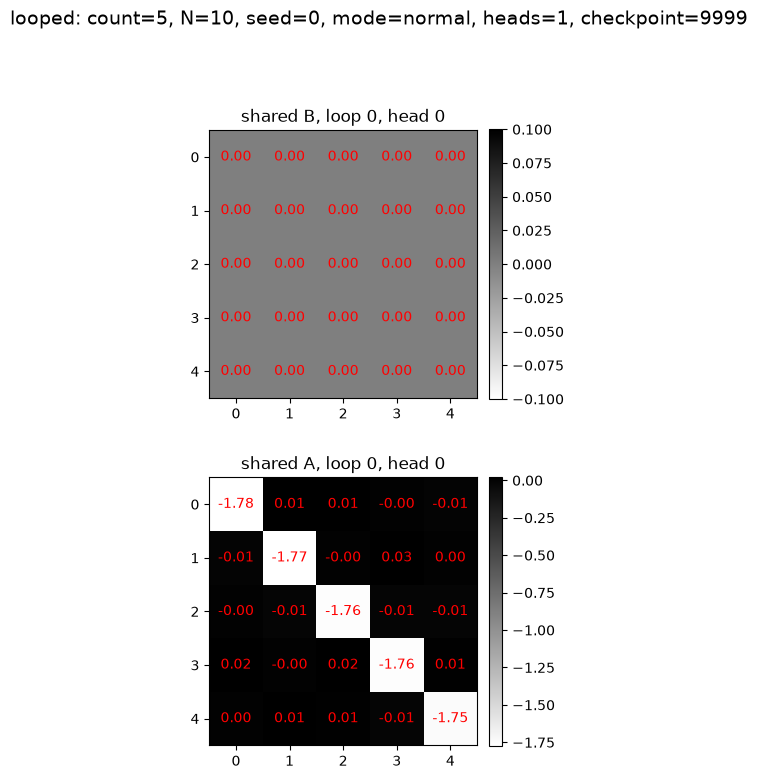

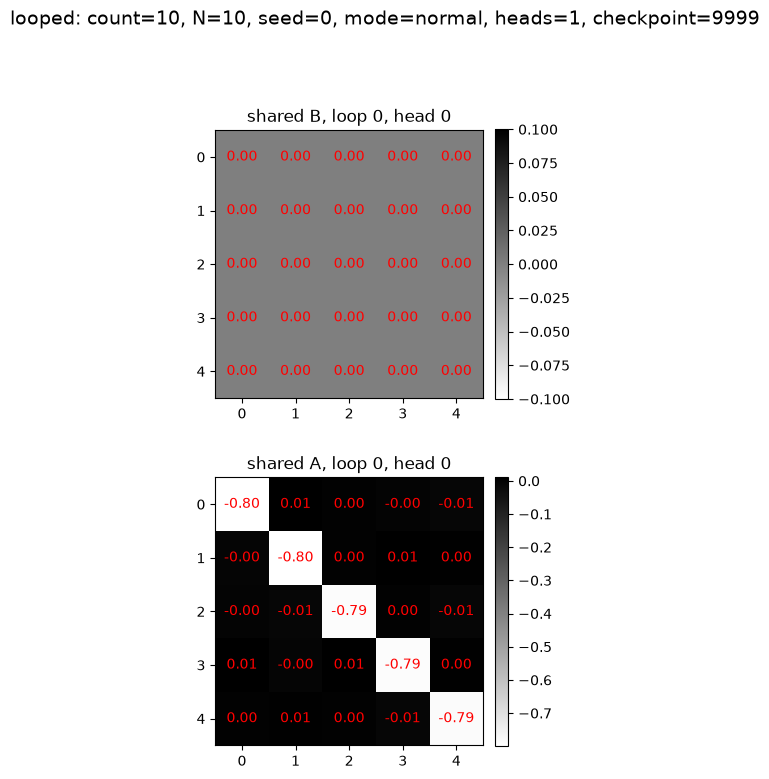

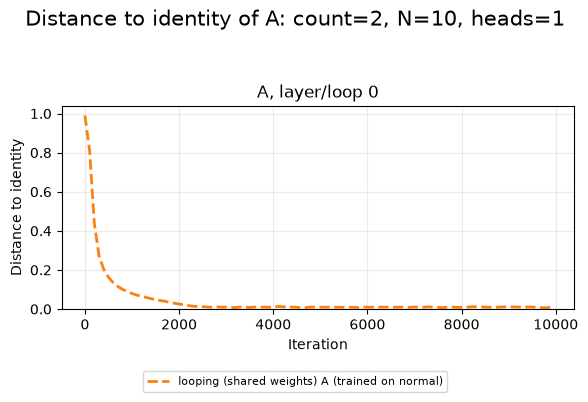

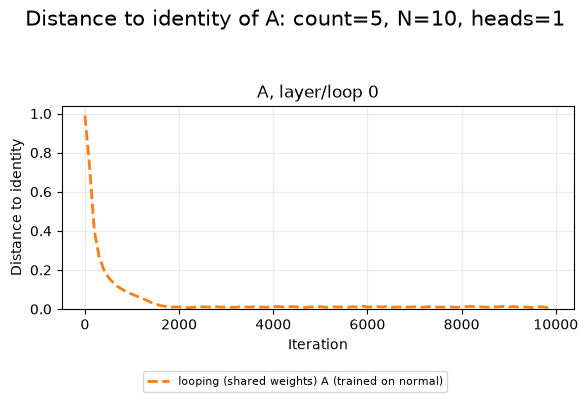

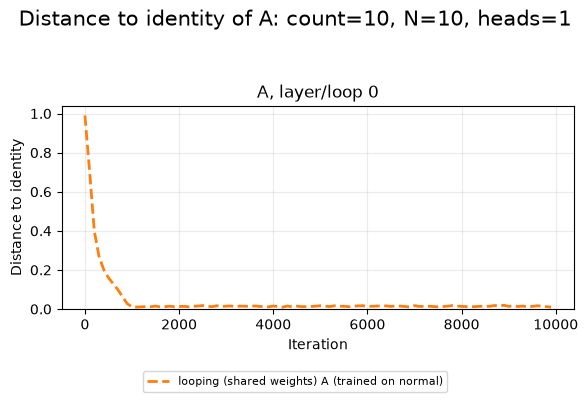

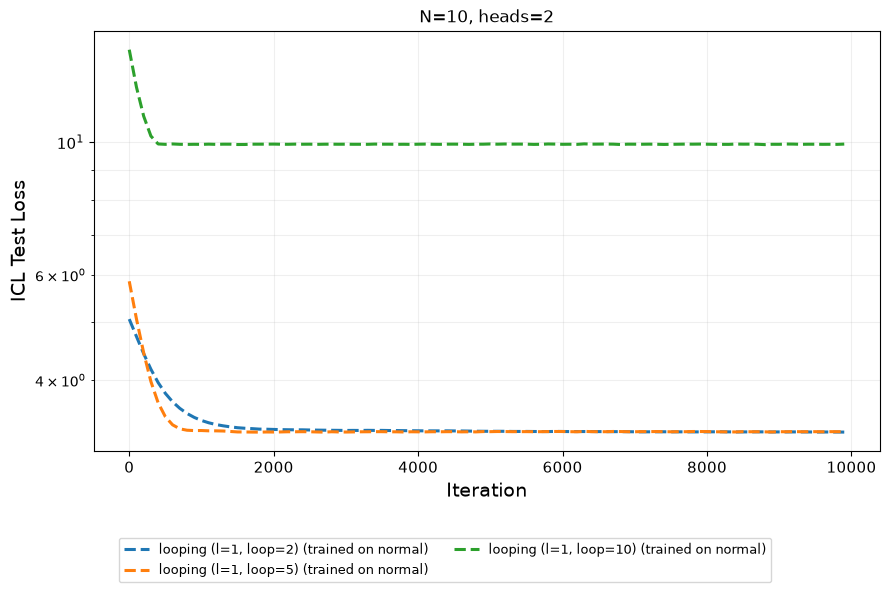

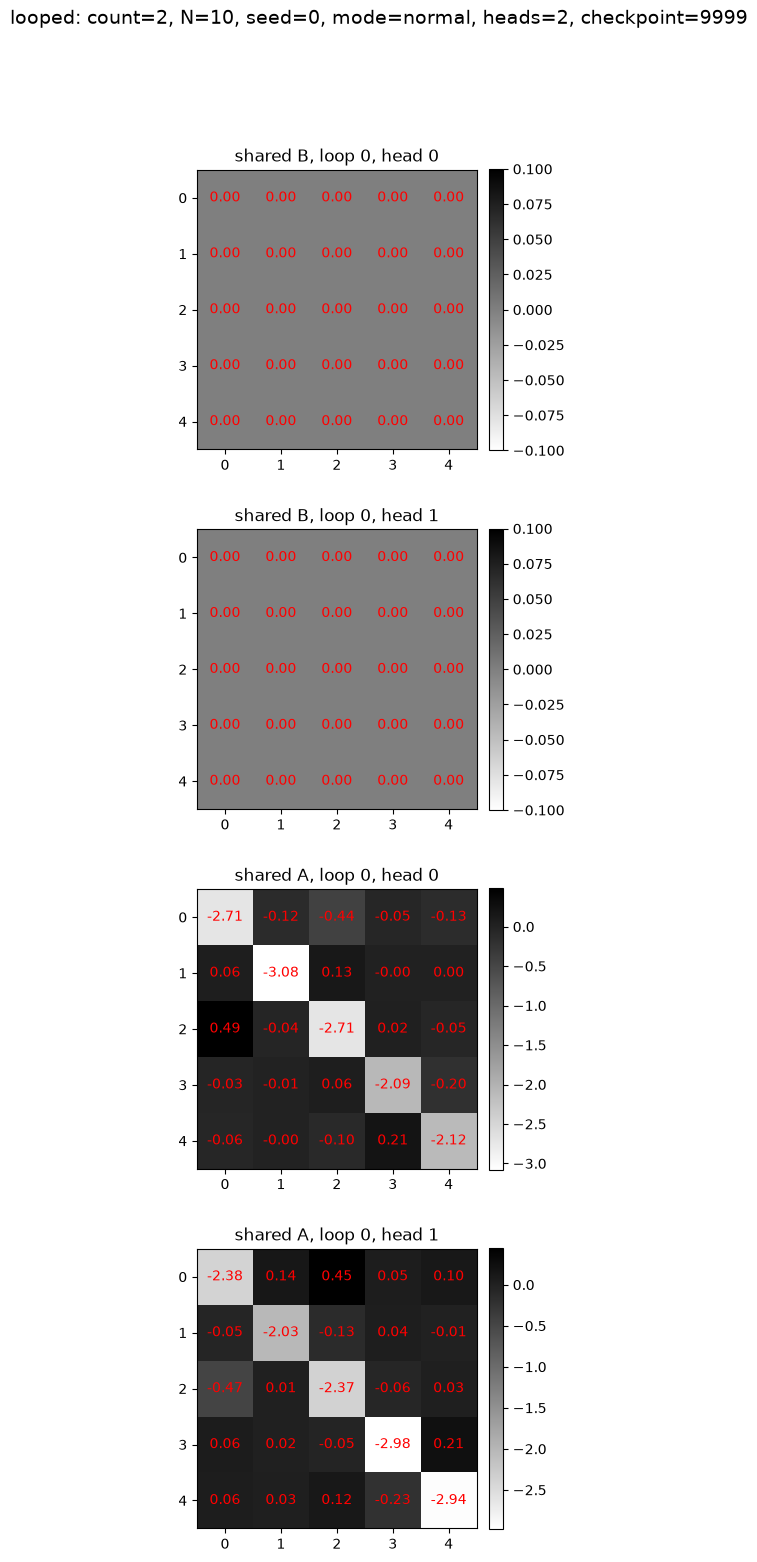

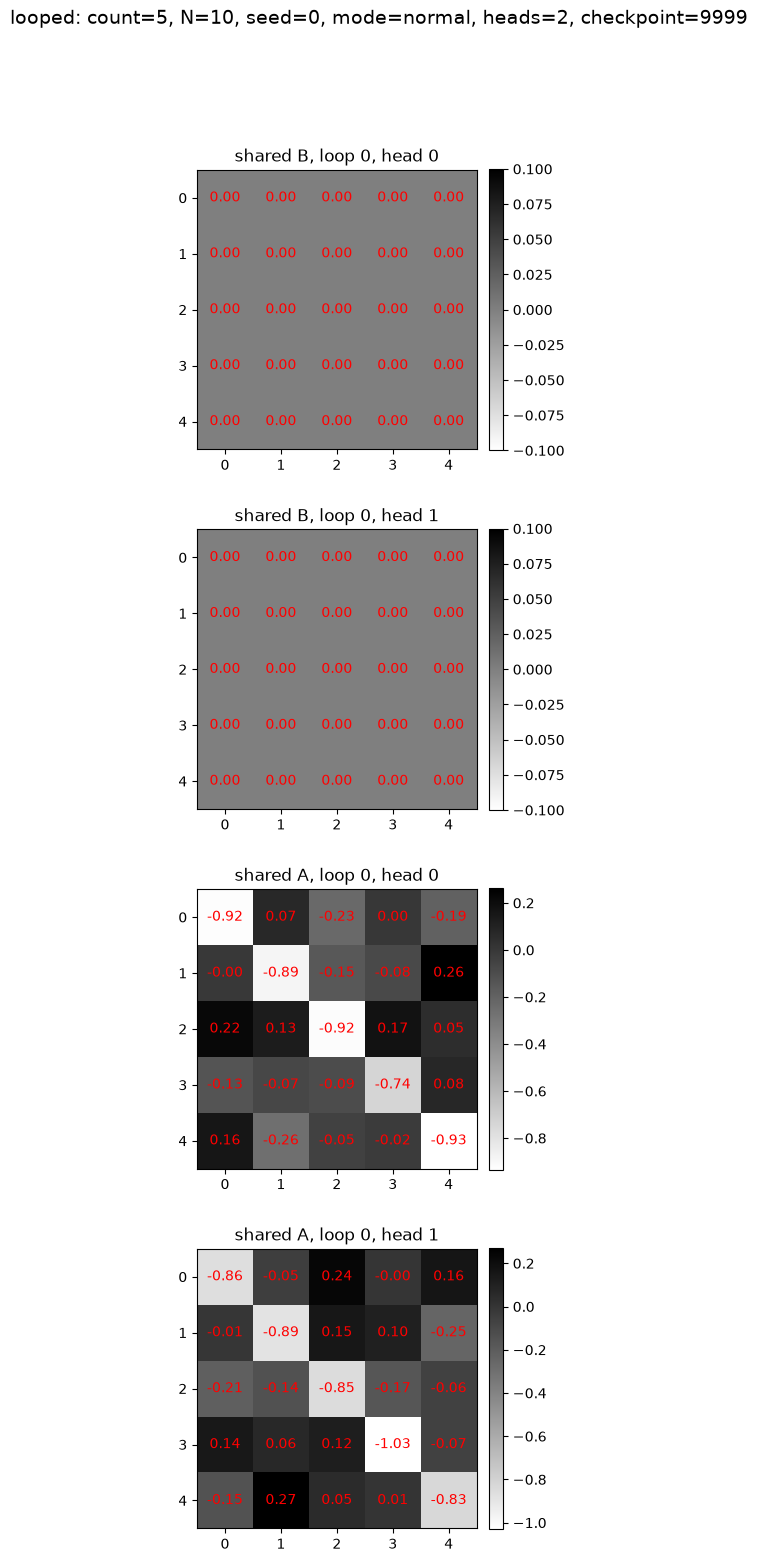

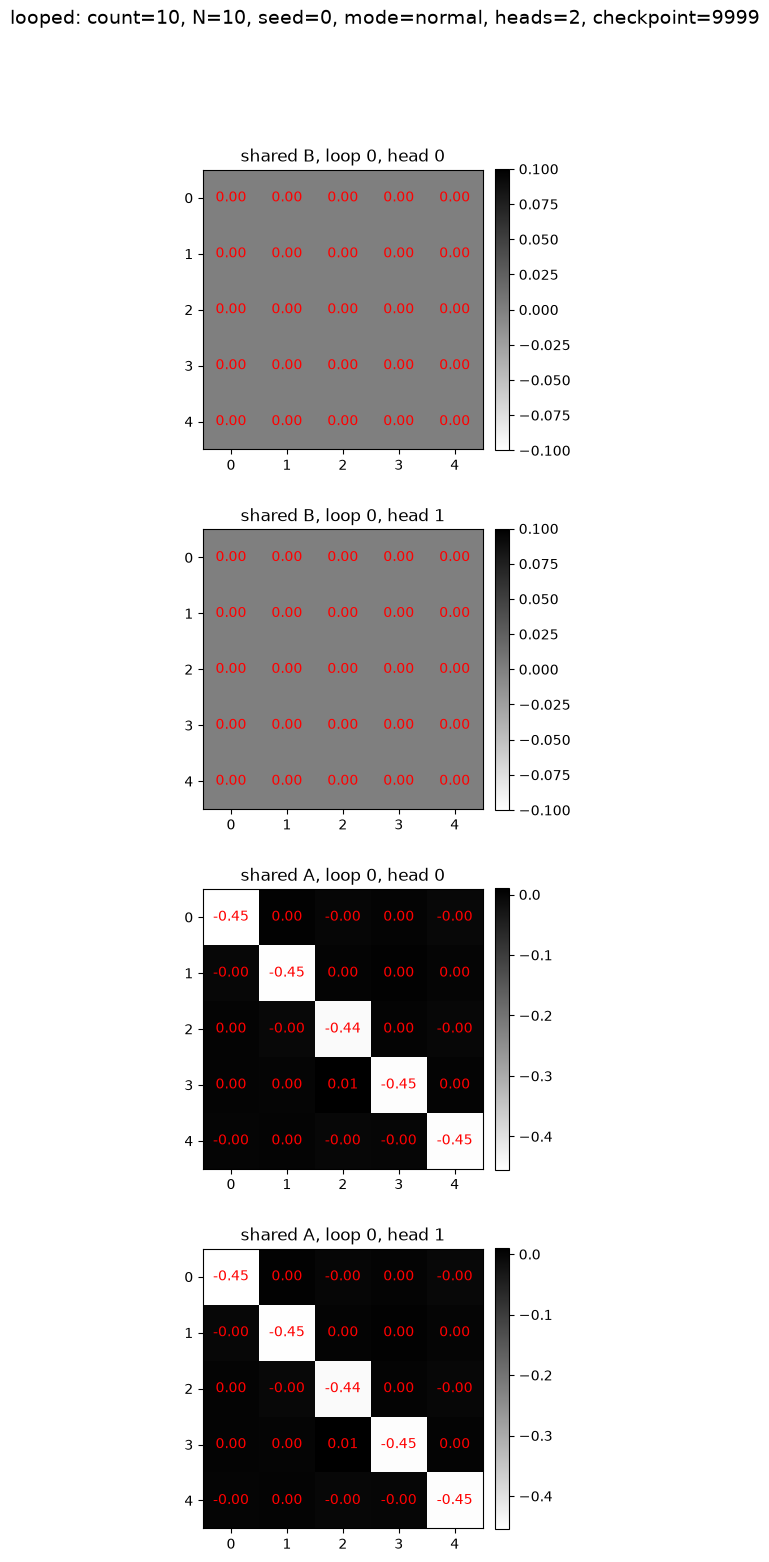

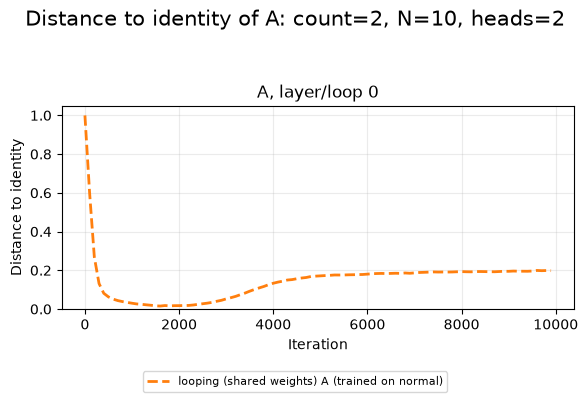

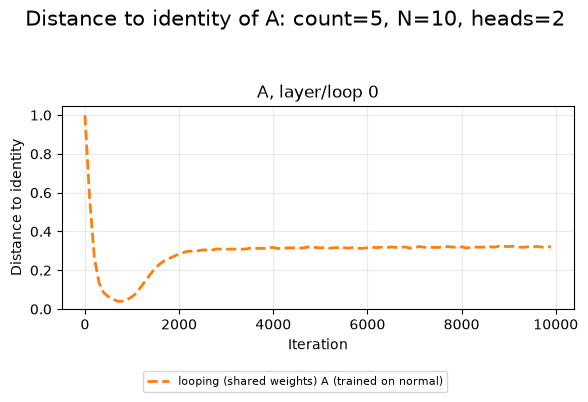

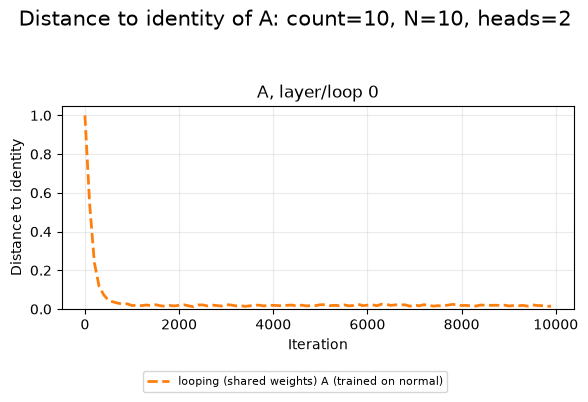

In [12]:
# Per-head-count plots: loss curves, parameter matrices, and distance to identity.
# The 1-headed results are plotted first.
for head_count in softmax_head_counts:
    head_fig_dir = os.path.join(softmax_fig_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)
    head_hist_dict = filter_by_head_count(softmax_hist_dict, head_count)

    plot_loss_curves(
        filter_by_head_count(softmax_loss_dict, head_count),
        softmax_counts,
        softmax_model_types,
        softmax_iterations,
        fig_dir=head_fig_dir,
        filename='softmax_test_loss_layered_vs_looped.pdf',
        head_count=head_count,
    )
    plot_parameter_matrices(
        head_hist_dict,
        softmax_seeds[0],
        softmax_counts,
        softmax_model_types,
        n_head=head_count,
        hist_stride=hist_stride,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )
    plot_dist_to_identity(
        softmax_dist_dicts[head_count],
        softmax_counts,
        softmax_iterations,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )

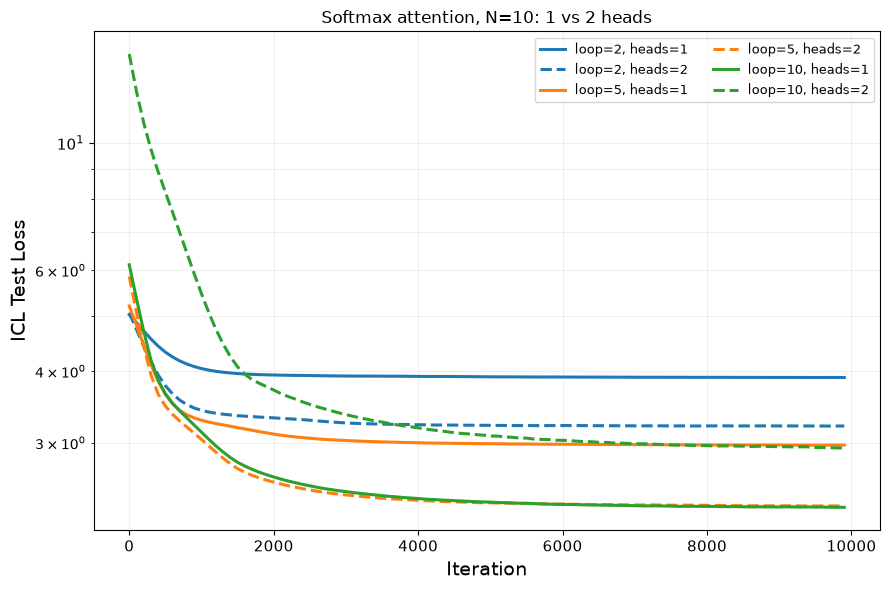

In [7]:
# Compare 1-headed and 2-headed softmax loss curves on the same graph.
# Color encodes the loop count; line style encodes the head count.
head_line_styles = dict(zip(softmax_head_counts, ['-', '--', ':', '-.']))
count_colors = dict(zip(softmax_counts, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))

for context_length in softmax_context_lengths:
    fig, ax = plt.subplots(figsize=(9, 6))
    for count in softmax_counts:
        for head_count in softmax_head_counts:
            run_keys = [
                key for key in softmax_loss_dict
                if key[1] == count and key[3] == context_length and key[5] == head_count
            ]
            if not run_keys:
                continue
            run_losses = torch.stack([softmax_loss_dict[key] for key in run_keys])
            # nanmean/nanstd over seeds so diverged runs do not hide the others.
            mean_loss = torch.nanmean(run_losses, dim=0)
            ax.plot(
                softmax_iterations, mean_loss.numpy(),
                color=count_colors[count], linestyle=head_line_styles[head_count], lw=2.2,
                label=f'loop={count}, heads={head_count}',
            )
            if len(run_keys) > 1:
                std_loss = torch.sqrt(torch.nanmean((run_losses - mean_loss) ** 2, dim=0))
                ax.fill_between(
                    softmax_iterations,
                    (mean_loss - std_loss).numpy(), (mean_loss + std_loss).numpy(),
                    color=count_colors[count], alpha=0.10,
                )

    ax.set_title(f'Softmax attention, N={context_length}: 1 vs 2 heads')
    ax.set_xlabel('Iteration', fontsize=14)
    ax.set_ylabel('ICL Test Loss', fontsize=14)
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.set_yscale('log')
    ax.grid(True, which='both', alpha=0.2)
    ax.legend(fontsize=9, ncol=2)
    fig.tight_layout()
    fig.savefig(
        os.path.join(
            softmax_fig_dir,
            f'softmax_test_loss_heads-{softmax_heads_tag}_N{context_length}.pdf',
        ),
        dpi=600,
    )
    plt.show()

Testing: (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 2, 'softmax')
Evaluated checkpoint (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 2, 'softmax') through 50 loops.
Testing: (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 2, 'softmax')
Evaluat

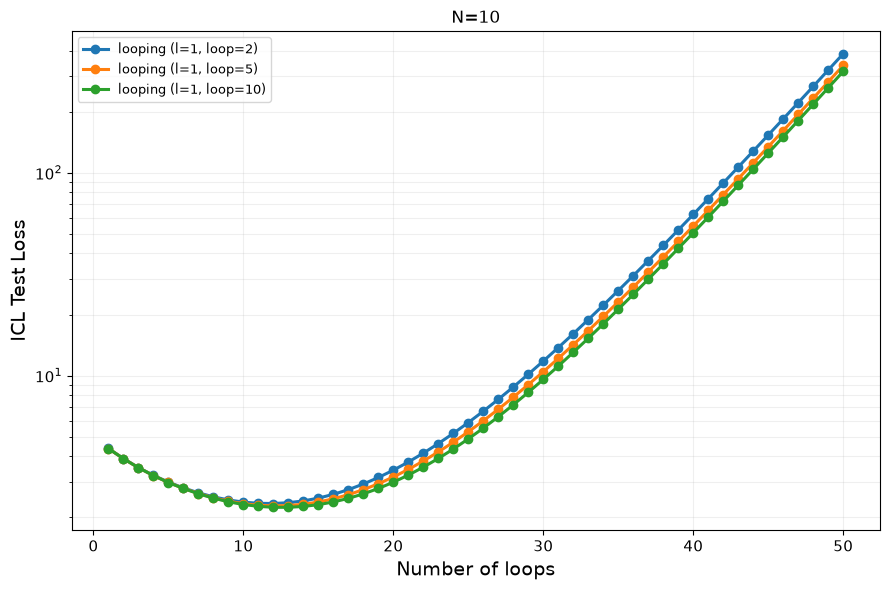

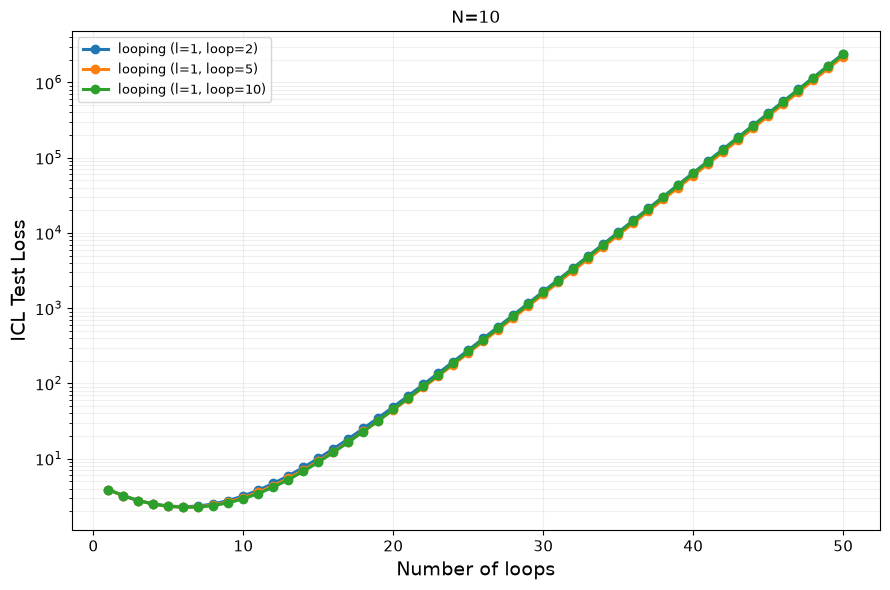

Saved softmax loop-count results to log/softmax_attention_loop_count_N10_d5_heads1-2_results.pth


In [8]:
# Evaluate final softmax looped checkpoints with 1 through 50 inference loops,
# separately for each head count.
softmax_looped_hist_dict = {
    key: history
    for key, history in softmax_hist_dict.items()
    if key[2] == 'looped' and key[-1] == 'softmax'
}

softmax_max_loops = 50
softmax_loop_loss_dict = compute_looped_loss_by_loop_count(
    softmax_looped_hist_dict,
    max_loops=softmax_max_loops,
    test_seed=TEST_SEED,
    attention_type='softmax',
)

softmax_loop_results_file = os.path.join(
    cur_dir,
    f'softmax_attention_loop_count_N{N}_d{d}_heads{softmax_heads_tag}_results.pth',
)
torch.save({
    'max_loops': softmax_max_loops,
    'test_seed': TEST_SEED,
    'attention_type': 'softmax',
    'head_counts': softmax_head_counts,
    'loss_dict': softmax_loop_loss_dict,
}, softmax_loop_results_file)

for head_count in softmax_head_counts:
    head_fig_dir = os.path.join(softmax_fig_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)
    plot_loop_loss_curves(
        filter_by_head_count(softmax_loop_loss_dict, head_count),
        n_layers_loops=softmax_counts,
        loop_counts=range(1, softmax_max_loops + 1),
        fig_dir=head_fig_dir,
        filename=f'softmax_test_loss_vs_loop_count_heads-{head_count}.pdf',
    )
print(f'Saved softmax loop-count results to {softmax_loop_results_file}')